# 03 — Efficiency Regressor Training (NLP schema)

Trains four candidate regressors — k-NN, decision tree, Random Forest, and Ridge
regression — on the **NLP-aware** synthetic dataset generated in notebook 01. The best
model is exported as `backend/app/ml/data/regressor_nlp.joblib` for use in the RL state
vector (notebook 04).

**What this model predicts:** `efficiency_ratio = actual_minutes / estimated_minutes`
for a given (task, worker) pair. Lower is better (the worker finishes faster than estimated).
The RL agent uses these predictions as one component of its state vector when deciding
which worker to assign a ticket to.

**What changed from the legacy schema:** The 8 `category_*` one-hot columns,
`proficiency_for_task_category`, and `is_primary_specialisation` are replaced by
`skill_match_score` (continuous, embedding-derived) and `is_strong_match` (binary
threshold at 0.65). The model now sees skill as a smooth signal rather than a hard
categorical lookup, which is the whole point of the NLP migration.


## 1 · Setup

Add `backend/` to `sys.path` and load the dataset from its parquet file.

In [10]:
import sys, json, warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "backend"))

# Suppress matplotlib font warnings (e.g., BLACK STAR glyph missing)
warnings.filterwarnings('ignore', message='.*Glyph.*')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error,
    r2_score, median_absolute_error,
)

from app.ml.regressors import KNNPredictor, DTPredictor, LinearPredictor, RFPredictor

sns.set_theme(style="whitegrid")
NLP_PARQUET = PROJECT_ROOT / "backend" / "app" / "ml" / "data" / "synthetic" / "synthetic_nlp.parquet"

if not NLP_PARQUET.exists():
    raise FileNotFoundError(
        f"{NLP_PARQUET} not found. Run notebook 01 (NLP section) to generate it."
    )

df = pd.read_parquet(NLP_PARQUET)
print(f"Loaded {len(df):,} rows, {len(df.columns)} columns from {NLP_PARQUET.name}")


Loaded 7,613 rows, 18 columns from synthetic_nlp.parquet


## 2 · Features and target

We use 11 features from the NLP-aware schema. `historical_efficiency` is excluded because
it is NaN for the vast majority of rows (cold-start: a worker needs 3+ completed tasks in
a category before the rolling average populates). Including a mostly-null feature would
degrade all models.

The feature set replaces the legacy 18-dim schema (8 category one-hots + proficiency
lookup + is_primary_specialisation) with a smaller, smoother signal driven by embedding
similarity.

Split: 75% train / 25% test, shuffled, seed 42.


In [11]:
# Load FEATURES from the file notebook 01 wrote — keeps the schema in one place.
FEATURES_FILE = PROJECT_ROOT / "backend" / "app" / "ml" / "data" / "synthetic" / "features_nlp.json"
if FEATURES_FILE.exists():
    FEATURES = json.loads(FEATURES_FILE.read_text())
    # Drop historical_efficiency — it's NaN for most cold-start rows.
    FEATURES = [f for f in FEATURES if f != "historical_efficiency"]
else:
    FEATURES = [
        "complexity", "priority_numeric", "estimated_minutes_norm",
        "requires_min_seniority",
        "seniority_numeric", "years_experience_norm",
        "skill_match_score", "is_strong_match",
        "base_productivity", "load_ratio_at_assignment",
    ]
TARGET = "efficiency_ratio"

print(f"Features ({len(FEATURES)}):")
for f in FEATURES:
    print(f"  - {f}")

clean = df[FEATURES + [TARGET]].dropna()
print(f"\nRows after dropna: {len(clean):,}  (dropped {len(df)-len(clean):,} rows)")

X = clean[FEATURES].to_numpy()
y = clean[TARGET].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)
print(f"Train: {X_train.shape}  Test: {X_test.shape}")


Features (10):
  - complexity
  - priority_numeric
  - estimated_minutes_norm
  - requires_min_seniority
  - seniority_numeric
  - years_experience_norm
  - skill_match_score
  - is_strong_match
  - base_productivity
  - load_ratio_at_assignment

Rows after dropna: 7,613  (dropped 0 rows)
Train: (5709, 10)  Test: (1904, 10)


## 3 · Regressor implementations

Each class in `backend/app/ml/regressors/` wraps a scikit-learn estimator and implements
`BaseEfficiencyPredictor`. The notebook never calls scikit-learn models directly — only
through these wrappers. This guarantees the RL agent can swap regressors without code
changes (Dependency Inversion, Open/Closed).

In [12]:
from app.ml.base.predictor import BaseEfficiencyPredictor

models: dict[str, BaseEfficiencyPredictor] = {
    "k-NN (k=7)":              KNNPredictor(n_neighbors=7),
    "Decision Tree (depth=8)": DTPredictor(max_depth=8),
    "Random Forest":           RFPredictor(n_estimators=100),
    "Ridge Regression":        LinearPredictor(alpha=1.0),
}

for name, model in models.items():
    assert isinstance(model, BaseEfficiencyPredictor), f"{name} does not implement BaseEfficiencyPredictor"
    print(f"{name}: {type(model).__name__} OK")

k-NN (k=7): KNNPredictor OK
Decision Tree (depth=8): DTPredictor OK
Random Forest: RFPredictor OK
Ridge Regression: LinearPredictor OK


## 4 · Train all four and compare

Fit each model on the training set and evaluate on the held-out test set.
Metrics: MAE (primary), RMSE, R², median absolute error.

                            MAE    RMSE      R2   MedAE
Random Forest            0.2524  0.4075  0.7283  0.1594
Decision Tree (depth=8)  0.2820  0.4503  0.6681  0.1747
Ridge Regression         0.2824  0.4352  0.6900  0.2055
k-NN (k=7)               0.3130  0.5122  0.5706  0.1939

Winner: Random Forest  (MAE margin over runner-up: 0.0296)


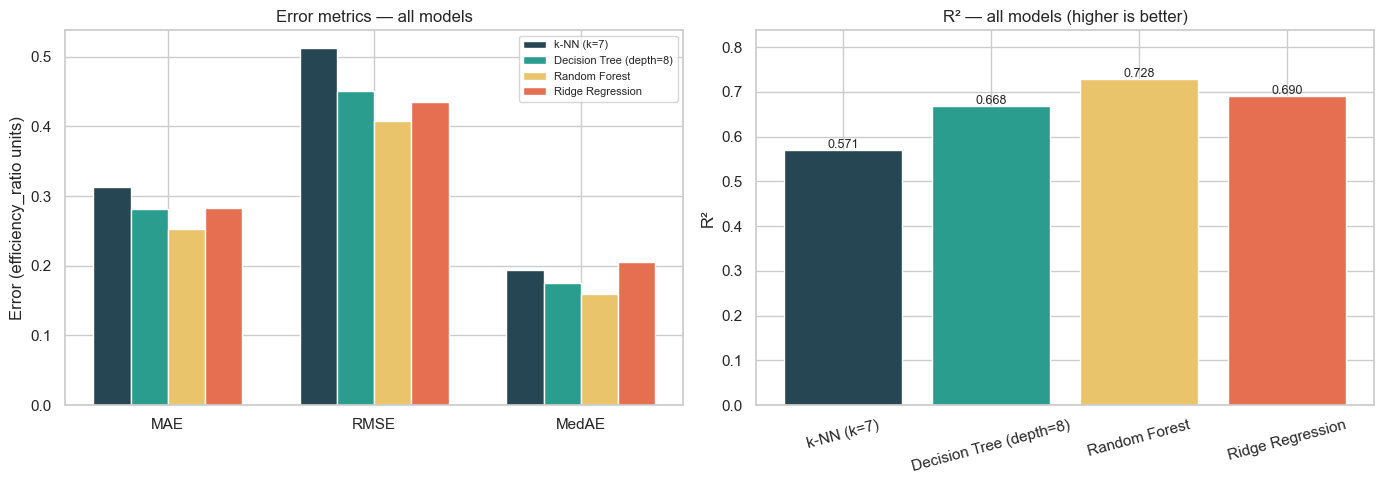

In [13]:
results: dict[str, dict] = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    results[name] = {
        "MAE":   mean_absolute_error(y_test, preds),
        "RMSE":  float(np.sqrt(mean_squared_error(y_test, preds))),
        "R2":    r2_score(y_test, preds),
        "MedAE": median_absolute_error(y_test, preds),
        "preds": preds,
    }

summary = pd.DataFrame(
    {k: {m: v for m, v in v.items() if m != "preds"} for k, v in results.items()}
).T.round(4)
print(summary.sort_values("MAE").to_string())

best_name = summary["MAE"].idxmin()
runner_up  = summary["MAE"].drop(best_name).idxmin()
margin = summary.loc[runner_up, "MAE"] - summary.loc[best_name, "MAE"]
print(f"\nWinner: {best_name}  (MAE margin over runner-up: {margin:.4f})")

# ── Comparison plots ──────────────────────────────────────────────────────────
metrics     = ["MAE", "RMSE", "MedAE"]
model_names = list(results.keys())
colors      = ["#264653", "#2a9d8f", "#e9c46a", "#e76f51"]

x     = np.arange(len(metrics))
width = 0.18

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: grouped error bars
for i, (name, color) in enumerate(zip(model_names, colors)):
    vals = [results[name][m] for m in metrics]
    axes[0].bar(x + i * width, vals, width, label=name, color=color)
axes[0].set_xticks(x + width * 1.5)
axes[0].set_xticklabels(metrics)
axes[0].set_ylabel("Error (efficiency_ratio units)")
axes[0].set_title("Error metrics — all models")
axes[0].legend(fontsize=8)

# Right: R²
r2_vals = [results[name]["R2"] for name in model_names]
axes[1].bar(model_names, r2_vals, color=colors)
axes[1].set_ylabel("R²")
axes[1].set_title("R² — all models (higher is better)")
axes[1].set_ylim(0, max(r2_vals) * 1.15)
for i, v in enumerate(r2_vals):
    axes[1].text(i, v + 0.005, f"{v:.3f}", ha="center", fontsize=9)
axes[1].tick_params(axis="x", labelrotation=15)

plt.tight_layout()
plt.show()

## 5 · Learning curves

MAE on the held-out test set as training size grows (5%→100%, 10 steps), for all four
models using the same colour scheme as section 4. This answers two questions: does adding
more data keep helping, and which model converges fastest? A curve that is still falling
steeply at 100% suggests generating more episodes in notebook 01 would improve accuracy.

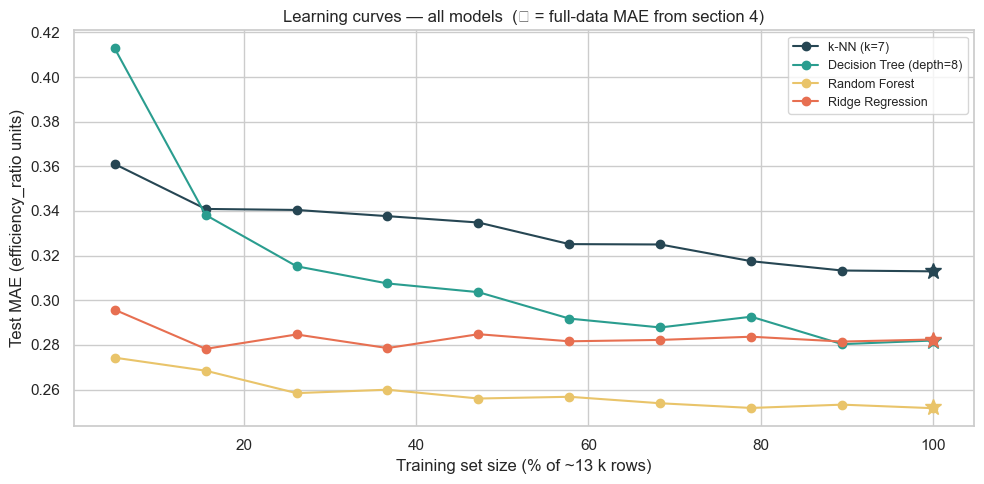

Model                            MAE @5%  MAE @100%     drop
k-NN (k=7)                        0.3610     0.3130  +0.0481
Decision Tree (depth=8)           0.4128     0.2820  +0.1309
Random Forest                     0.2743     0.2517  +0.0226
Ridge Regression                  0.2958     0.2824  +0.0133


In [14]:
fracs       = np.linspace(0.05, 1.0, 10)
model_names = list(models.keys())
colors      = ["#264653", "#2a9d8f", "#e9c46a", "#e76f51"]

# Compute curves once, reuse for plot + commentary
curves: dict[str, list[float]] = {}
for name in model_names:
    model_cls  = type(models[name])
    curve_maes = []
    for frac in fracs:
        n   = max(20, int(frac * len(X_train)))
        idx = np.random.default_rng(42).choice(len(X_train), size=n, replace=False)
        m   = model_cls()
        m.fit(X_train[idx], y_train[idx])
        curve_maes.append(mean_absolute_error(y_test, m.predict(X_test)))
    curves[name] = curve_maes

fig, ax = plt.subplots(figsize=(10, 5))
for name, color in zip(model_names, colors):
    ax.plot(fracs * 100, curves[name], marker="o", label=name, color=color)
    # Star anchors each line to the full-data MAE reported in section 4
    ax.plot(100, results[name]["MAE"], marker="*", markersize=12, color=color)

ax.set_xlabel("Training set size (% of ~13 k rows)")
ax.set_ylabel("Test MAE (efficiency_ratio units)")
ax.set_title("Learning curves — all models  (★ = full-data MAE from section 4)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

print(f"{'Model':30s}  {'MAE @5%':>8}  {'MAE @100%':>9}  {'drop':>7}")
for name in model_names:
    c = curves[name]
    print(f"{name:30s}  {c[0]:8.4f}  {c[-1]:9.4f}  {c[0]-c[-1]:+7.4f}")

## 6 · Feature importance

`skill_match_score` is expected to rank near the top in both models because the
simulation formula makes it the dominant driver of actual time (it replaces the legacy
proficiency lookup). If it doesn't appear in the top 3, that would suggest a bug in the
formula or an issue with the embedding rescaling.


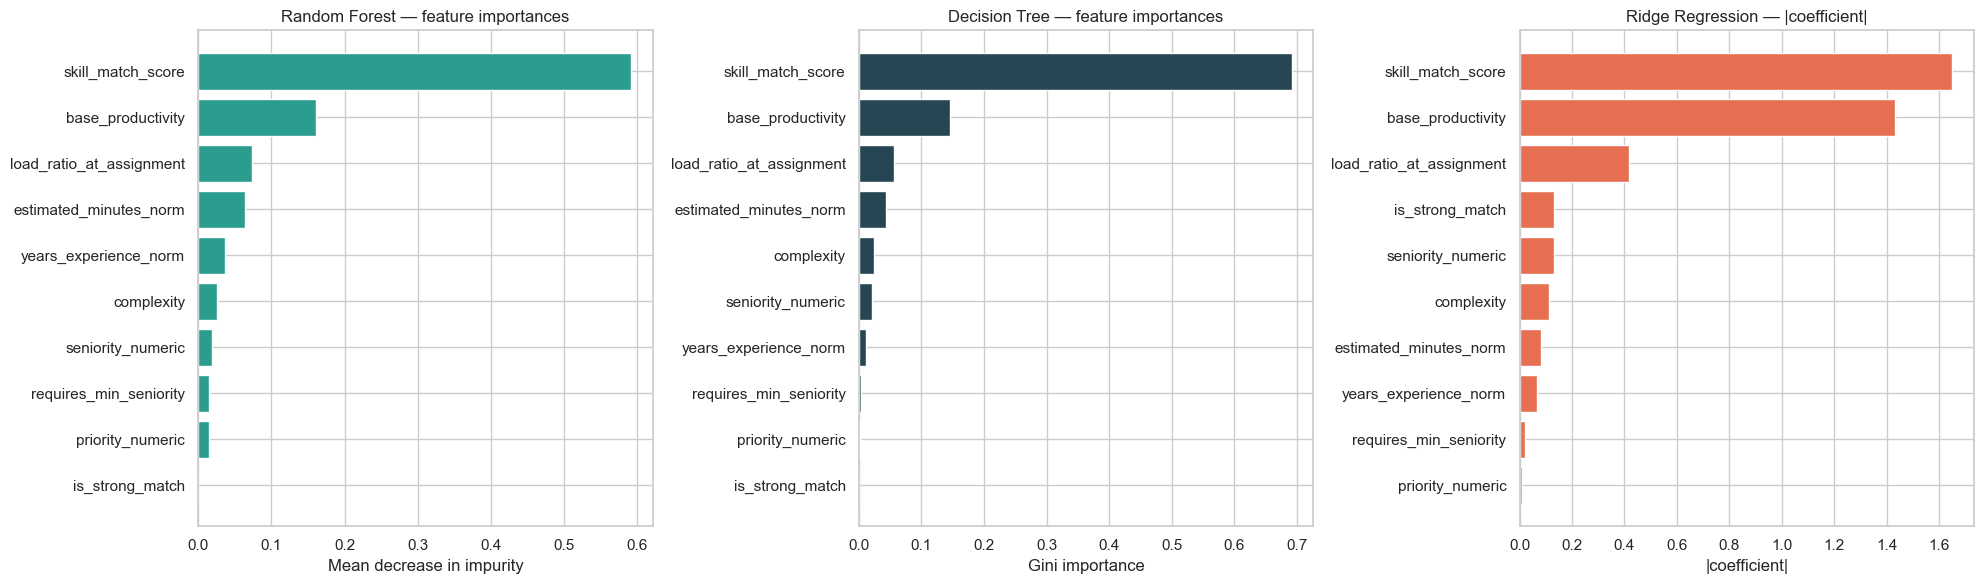

RF top-3:  ['skill_match_score', 'base_productivity', 'load_ratio_at_assignment']
DT top-3:  ['skill_match_score', 'base_productivity', 'load_ratio_at_assignment']
Linear top: skill_match_score
skill_match_score is in RF top-3 as expected


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Random Forest importances (winner)
rf_model = models["Random Forest"]
assert isinstance(rf_model, RFPredictor)
rf_imp = rf_model.feature_importances()
order_rf = np.argsort(rf_imp)
axes[0].barh([FEATURES[i] for i in order_rf], rf_imp[order_rf], color="#2a9d8f")
axes[0].set_title("Random Forest — feature importances")
axes[0].set_xlabel("Mean decrease in impurity")

# Decision Tree importances
dt_model = models["Decision Tree (depth=8)"]
assert isinstance(dt_model, DTPredictor)
importances = dt_model.feature_importances()
order_dt = np.argsort(importances)
axes[1].barh([FEATURES[i] for i in order_dt], importances[order_dt], color="#264653")
axes[1].set_title("Decision Tree — feature importances")
axes[1].set_xlabel("Gini importance")

# Ridge absolute coefficients
lin_model = models["Ridge Regression"]
assert isinstance(lin_model, LinearPredictor)
abs_coef = np.abs(lin_model.coef())
order_lin = np.argsort(abs_coef)
axes[2].barh([FEATURES[i] for i in order_lin], abs_coef[order_lin], color="#e76f51")
axes[2].set_title("Ridge Regression — |coefficient|")
axes[2].set_xlabel("|coefficient|")

plt.tight_layout()
plt.show()

rf_top3 = [FEATURES[i] for i in np.argsort(rf_imp)[-3:][::-1]]
dt_top3 = [FEATURES[i] for i in np.argsort(importances)[-3:][::-1]]
print(f"RF top-3:  {rf_top3}")
print(f"DT top-3:  {dt_top3}")
print(f"Linear top: {FEATURES[int(np.argmax(abs_coef))]}")

if "skill_match_score" not in rf_top3:
    print("!! UNEXPECTED: skill_match_score not in RF top-3 — review formula / rescaling")
else:
    print("skill_match_score is in RF top-3 as expected")


## 7 · Residual analysis

For the best model we inspect where predictions are systematically wrong. The RL agent
cares about *relative* ranking of workers, not absolute accuracy — so moderate bias at
the tails is acceptable. What we must not see: systematic bias correlated with
`skill_match_score` (that would mean the model is mis-ranking workers).


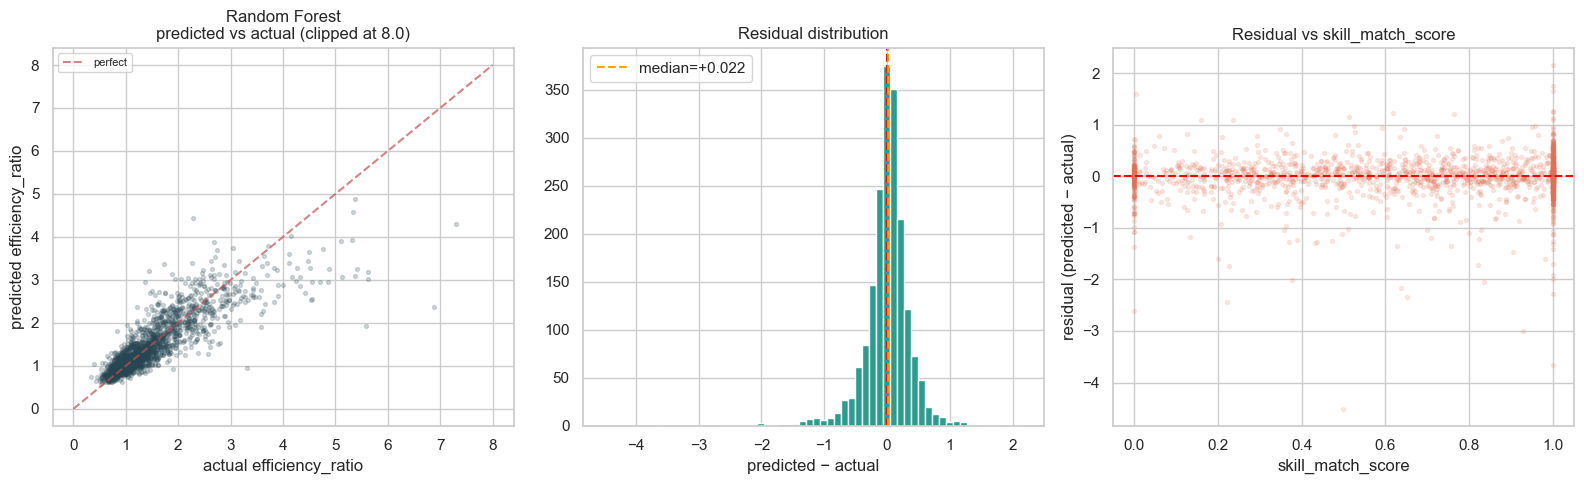

Residual median: +0.0218  mean: -0.0061
Bias at low skill (<0.3): -0.0321


In [16]:
best_model = models[best_name]
best_preds = results[best_name]["preds"]
residuals  = best_preds - y_test

# Clip for readability
cap = 8.0
y_cap   = np.clip(y_test,   0, cap)
p_cap   = np.clip(best_preds, 0, cap)
skill_test = clean[FEATURES]["skill_match_score"].iloc[len(X_train):].to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1 — predicted vs actual
axes[0].scatter(y_cap, p_cap, alpha=0.2, s=8, color="#264653")
lim = cap
axes[0].plot([0, lim], [0, lim], "r--", alpha=0.7, label="perfect")
axes[0].set_xlabel("actual efficiency_ratio")
axes[0].set_ylabel("predicted efficiency_ratio")
axes[0].set_title(f"{best_name}\npredicted vs actual (clipped at {cap})")
axes[0].legend(fontsize=8)

# 2 — residual histogram
axes[1].hist(np.clip(residuals, -cap, cap), bins=60, edgecolor="white", color="#2a9d8f")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].axvline(np.median(residuals), color="orange", linestyle="--",
                label=f"median={np.median(residuals):+.3f}")
axes[1].set_xlabel("predicted − actual")
axes[1].set_title("Residual distribution")
axes[1].legend()

# 3 — residual vs skill_match_score
axes[2].scatter(
    skill_test,
    np.clip(residuals, -cap, cap),
    alpha=0.15, s=8, color="#e76f51",
)
axes[2].axhline(0, color="red", linestyle="--")
axes[2].set_xlabel("skill_match_score")
axes[2].set_ylabel("residual (predicted − actual)")
axes[2].set_title("Residual vs skill_match_score")

plt.tight_layout()
plt.show()

print(f"Residual median: {np.median(residuals):+.4f}  mean: {np.mean(residuals):+.4f}")
print(f"Bias at low skill (<0.3): "
      f"{np.mean(residuals[skill_test < 0.3]):+.4f}")


> **Interpretation note**: if the model systematically *underpredicts* at high
> `efficiency_ratio` values (i.e. underestimates how slow a worker will be on hard
> assignments), that is acceptable at this stage. The RL agent compensates through
> its learned Q-values: a worker consistently assigned to tasks where they overrun
> will accumulate negative reward signal, driving the policy away from that assignment
> regardless of the regressor's bias. The regressor's primary value is *relative
> ranking* of workers, not absolute minute-accuracy.

## 8 · Export best model

Persist the winning regressor and the feature-column list. The RL state builder (notebook
04) loads both to ensure it passes exactly the same columns in the same order.

In [17]:
from app.ml.base.predictor import BaseEfficiencyPredictor

MODEL_DIR = PROJECT_ROOT / "backend" / "app" / "ml" / "data"
MODEL_DIR.mkdir(exist_ok=True)

joblib.dump(best_model, MODEL_DIR / "regressor_nlp.joblib")
print("Saved:", MODEL_DIR / "regressor_nlp.joblib")

(MODEL_DIR / "regressor_nlp_features.json").write_text(json.dumps(FEATURES))
print("Saved:", MODEL_DIR / "regressor_nlp_features.json")

# Sanity-check round-trip
loaded = joblib.load(MODEL_DIR / "regressor_nlp.joblib")
assert isinstance(loaded, BaseEfficiencyPredictor)
roundtrip_mae = mean_absolute_error(y_test, loaded.predict(X_test))
print(f"Round-trip MAE: {roundtrip_mae:.4f}  (expected: {results[best_name]['MAE']:.4f})")


Saved: C:\Projects\Clarity\backend\app\ml\data\regressor_nlp.joblib
Saved: C:\Projects\Clarity\backend\app\ml\data\regressor_nlp_features.json
Round-trip MAE: 0.2524  (expected: 0.2524)


## 9 · Summary

Summarises what was trained, what the numbers mean, and what comes next.

In [18]:
runner_up_name = summary["MAE"].drop(best_name).idxmin()
mae_margin = summary.loc[runner_up_name, "MAE"] - summary.loc[best_name, "MAE"]

# Use RF top-3 if RF won, else DT top-3 as proxy
winner_model = models[best_name]
if isinstance(winner_model, RFPredictor):
    top3 = [FEATURES[i] for i in np.argsort(winner_model.feature_importances())[-3:][::-1]]
elif isinstance(winner_model, DTPredictor):
    top3 = [FEATURES[i] for i in np.argsort(winner_model.feature_importances())[-3:][::-1]]
else:
    top3 = dt_top3
skill_top = "skill_match_score" in top3

print("=" * 60)
print("REGRESSOR TRAINING SUMMARY (NLP schema)")
print("=" * 60)
print(f"Winner:              {best_name}")
print(f"Test MAE:            {results[best_name]['MAE']:.4f} ratio units")
print(f"Test MedAE:          {results[best_name]['MedAE']:.4f} ratio units")
print(f"Test R²:             {results[best_name]['R2']:.4f}")
print(f"Margin over runner-up ({runner_up_name}): {mae_margin:.4f}")
print()
print(f"Practical meaning:   Median prediction error is "
      f"{results[best_name]['MedAE']:.2f} × estimated_minutes.")
print(f"  e.g. for a 4-hour task, the model's typical error is "
      f"±{results[best_name]['MedAE']*240:.0f} min.")
print()
print(f"Winner top-3 features: {top3}")
print(f"skill_match_score in top-3: {skill_top} (expected: True)")
print()
print("Downstream use:      The exported regressor_nlp.joblib is loaded by the RL")
print("  state builder (notebook 04) to produce predicted_eff_norm as one")
print("  component of the (task, worker) state vector fed to the Q-network.")


REGRESSOR TRAINING SUMMARY (NLP schema)
Winner:              Random Forest
Test MAE:            0.2524 ratio units
Test MedAE:          0.1594 ratio units
Test R²:             0.7283
Margin over runner-up (Decision Tree (depth=8)): 0.0296

Practical meaning:   Median prediction error is 0.16 × estimated_minutes.
  e.g. for a 4-hour task, the model's typical error is ±38 min.

Winner top-3 features: ['skill_match_score', 'base_productivity', 'load_ratio_at_assignment']
skill_match_score in top-3: True (expected: True)

Downstream use:      The exported regressor_nlp.joblib is loaded by the RL
  state builder (notebook 04) to produce predicted_eff_norm as one
  component of the (task, worker) state vector fed to the Q-network.
